In [1]:
import sys
import mne
import PyQt5

from pathlib import Path
from autoreject import AutoReject, get_rejection_threshold

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

parent = Path.cwd().parent
sys.path.append(str(parent))

from downloader import download_and_extract_all

## Download and Data Exploration

In [2]:
data = None
columns = ['id', 'event', 'device', 'channel', 'code', 'size', 'data']

if Path('./data/mnist.csv').exists():
    data = pd.read_csv('./data/mnist.csv')
    
else:
    eeg_mnist_urls = ['https://mindbigdata.com/opendb/MindBigData-MW-v1.0.zip', 'https://mindbigdata.com/opendb/MindBigData-EP-v1.0.zip', 'https://mindbigdata.com/opendb/MindBigData-MU-v1.0.zip', 'https://mindbigdata.com/opendb/MindBigData-IN-v1.06.zip']
    eeg_mnist_paths = ['./data/EEG_MNIST/MW/', './data/EEG_MNIST/EP/', './data/EEG_MNIST/MU', './data/EEG_MNIST/IN/']
    response = await download_and_extract_all(eeg_mnist_urls, eeg_mnist_paths, use_tqdm=True, concurrency_limit=None, retries=False)
    print(response)

    paths = ['./data/EEG_MNIST/EP/EP1.01.txt', './data/EEG_MNIST/IN/IN.txt', './data/EEG_MNIST/MU/MU.txt', './data/EEG_MNIST/MW/MW.txt']
    data = pd.concat([pd.read_csv(p, delimiter='\t', names=columns, header=None) for p in paths])
    data.to_csv('./data/mnist.csv', index=None)
    for p in paths:
        Path('./data/EEG_MNIST').unlink()
        Path(p).parent.rmdir()
    Path('./data/EEG_MNIST').rmdir()

data = data.set_index('id')
data = data.sort_index()

In [3]:
data.head(10)

,event,device,channel,code,size,data
id,,,,,,
0,0,MW,FP1,0,1017,"38,48,51,44,48,56,56,41,20,-3,-9,-1,6,5,6,17,2..."
1,1,MW,FP1,1,889,"83,74,65,65,66,55,43,25,18,20,26,33,41,38,28,3..."
2,2,MW,FP1,4,1017,"19,10,-2,-9,-5,3,8,7,8,2,-10,-21,-22,-27,-30,-..."
3,3,MW,FP1,1,1017,"17,29,36,26,21,17,17,13,17,21,25,26,20,5,-5,-1..."
4,4,MW,FP1,8,952,"77,74,69,70,76,75,76,75,67,66,76,93,98,82,55,3..."
5,5,MW,FP1,4,1015,"60,59,59,55,36,18,12,20,23,6,-10,-11,-6,-5,-7,..."
6,6,MW,FP1,5,952,"-68,-65,-55,-52,-60,-67,-58,-46,-28,-19,-19,-2..."
7,7,MW,FP1,4,1015,"75,69,53,35,24,27,41,53,51,32,18,4,-4,-1,10,22..."
8,8,MW,FP1,0,889,"123,107,84,64,59,71,71,72,77,80,58,32,16,8,12,..."


In [4]:
num_channels = data['channel'].unique().shape[0]
device_sampling_rates = {'EP' : 128,'MW' : 512,'MU' : 220,'IN' : 128} #visible on the webpage of the dataset and on device manuals
sorted_channels = data['channel'].unique().tolist()

In [5]:
#for further use we convert the data for each device into event-related format
device_wise_raw = {}
device_wise_events = {}

for device in data['device'].unique():
    ddata = data[data['device'] == device]

    n_channels = len(ddata['channel'].unique())

    evsplits = np.array([0]+ddata[ddata['channel'] == ddata['channel'].iloc[0]]['size'].cumsum().values.tolist()).astype(np.int32) #all channels have same splits
    labels = ddata[ddata['channel'] == ddata['channel'].iloc[0]]['code'].values.astype(np.int32) #same applies for number codons

    device_wise_events[device] = np.concat([np.expand_dims(evsplits[:-1], axis=1), np.expand_dims(np.zeros_like(evsplits[:-1]), axis=1), np.expand_dims(labels, axis=1)], axis=1)

    if not Path(f'./data/mnist_{device}_raw.fif').exists():
        device_arr = np.empty((n_channels, ddata[ddata['channel'] == ddata['channel'].iloc[0]]['size'].sum(), ), dtype=np.float64)
        channel_names = []
        for cid, channel in enumerate(ddata['channel'].unique()):
            for i, entry in enumerate(ddata[ddata['channel'] == channel]['data']):
                device_arr[cid][evsplits[i]:evsplits[i+1]] = [float(f) for f in entry.split(',')]
            channel_names.append(channel)

        info = mne.create_info(channel_names, sfreq=device_sampling_rates[device])

        raw = mne.io.RawArray(device_arr, info, first_samp=0)
        raw = raw.set_channel_types({c: 'eeg' for c in channel_names}, on_unit_change='ignore')
        raw = raw.set_montage('colin27_1020', match_case=False, on_missing='warn')
        raw.save(f'./data/mnist_{device}_raw.fif')
        device_wise_raw[device] = raw
    else:
        raw = mne.io.read_raw(f'./data/mnist_{device}_raw.fif', preload=True)
        device_wise_raw[device] = raw

Opening raw data file ./data/mnist_MW_raw.fif...
    Range : 0 ... 66078015 =      0.000 ... 129058.623 secs
Ready.
Reading 0 ... 66078015  =      0.000 ... 129058.623 secs...
Opening raw data file ./data/mnist_EP_raw.fif...
    Range : 0 ... 16877096 =      0.000 ... 131852.312 secs
Ready.
Reading 0 ... 16877096  =      0.000 ... 131852.312 secs...
Opening raw data file ./data/mnist_MU_raw.fif...
    Range : 0 ... 19196422 =      0.000 ... 87256.464 secs
Ready.
Reading 0 ... 19196422  =      0.000 ... 87256.464 secs...
Opening raw data file ./data/mnist_IN_raw.fif...
    Range : 0 ... 3185965 =      0.000 ... 24890.352 secs
Ready.
Reading 0 ... 3185965  =      0.000 ... 24890.352 secs...


In [6]:
#enable for interactive plot which allows for proper analysis
# %matplotlib qt
%matplotlib inline

#most devices have no clear voltage resolution listed
#EP resolution (manual): 0,1275µV (https://www.emotiv.com/de/epoc-x#techspec)
#scalings used here for visual clarity
device_scalings = {'MW' : 1000,'EP' : 100,'MU' : 100,'IN' : 100}

## Analysis for further usage

### MW device
Data overall usagle with cleaning, some artifacts in trials. However, since it is a single-electrode recording and too sparse I will not utilize this data for now.

Using matplotlib as 2D backend.


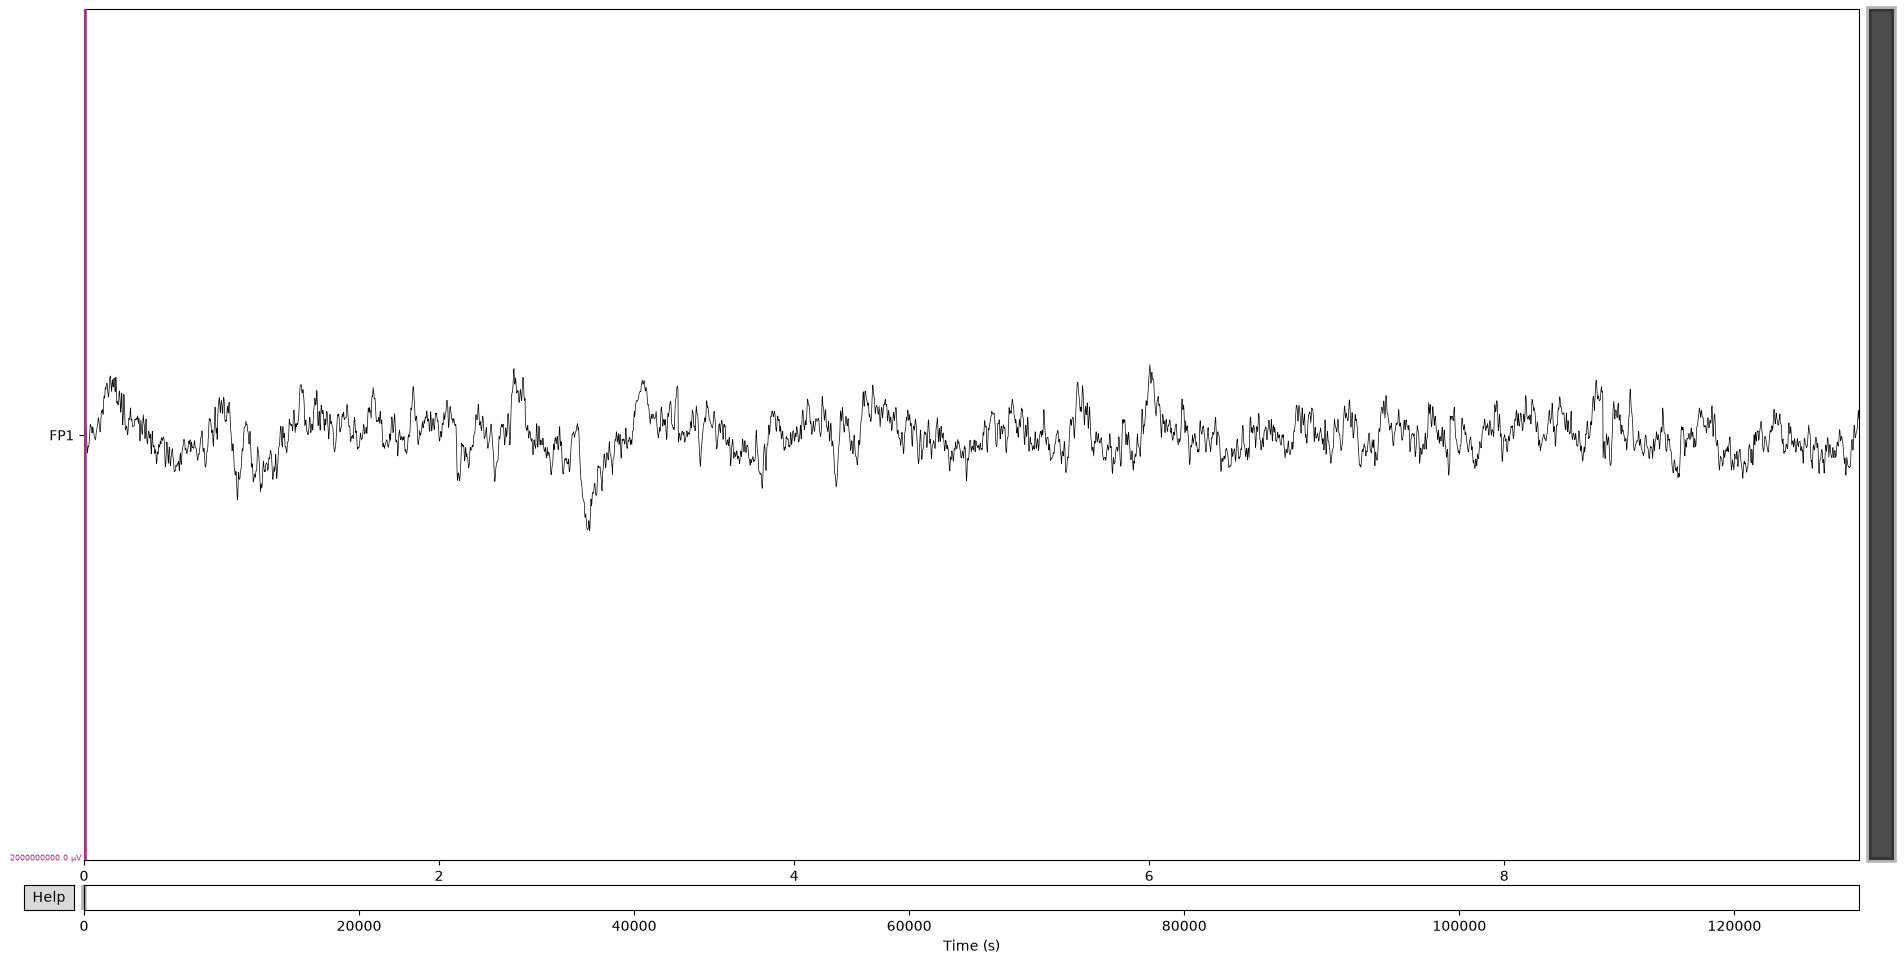

Effective window size : 4.000 (s)
Plotting power spectral density (dB=True).
Need more than one channel to make topography for eeg. Disabling interactivity.


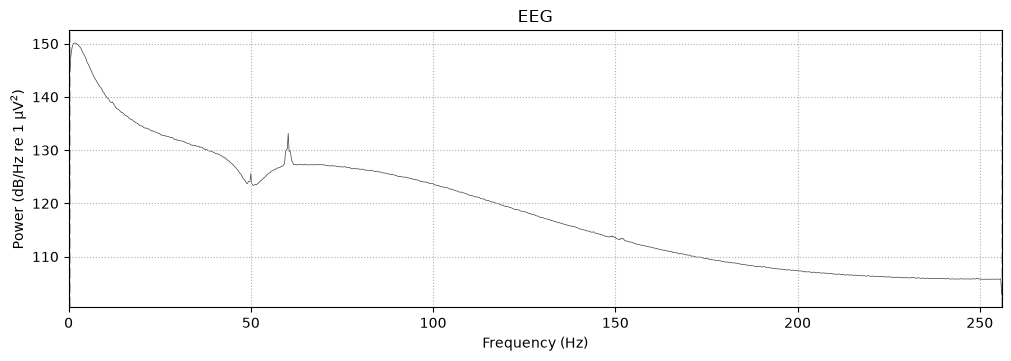

In [7]:
device_wise_raw['MW'].plot(scalings=dict(eeg=device_scalings['MW']))
device_wise_raw['MW'].compute_psd(picks=None, fmax=device_sampling_rates['MW']//2).plot(picks=None, exclude='bads', amplitude=False)
print('\n')

### EP device
Richest dataset by far. Filtering should get rid of a lot of noise. EOG and ECG channels are non-existent sadly but I may be able to still clean up a bit using the FP1 and FP2 channels and MNE methods. Power spectrum density function is looking good overall, no major issues and prominent harmonics thereof in the relevant spectrum. Some trials are quite noisy though and need to be removed in the end most likely (maybe ~5%).

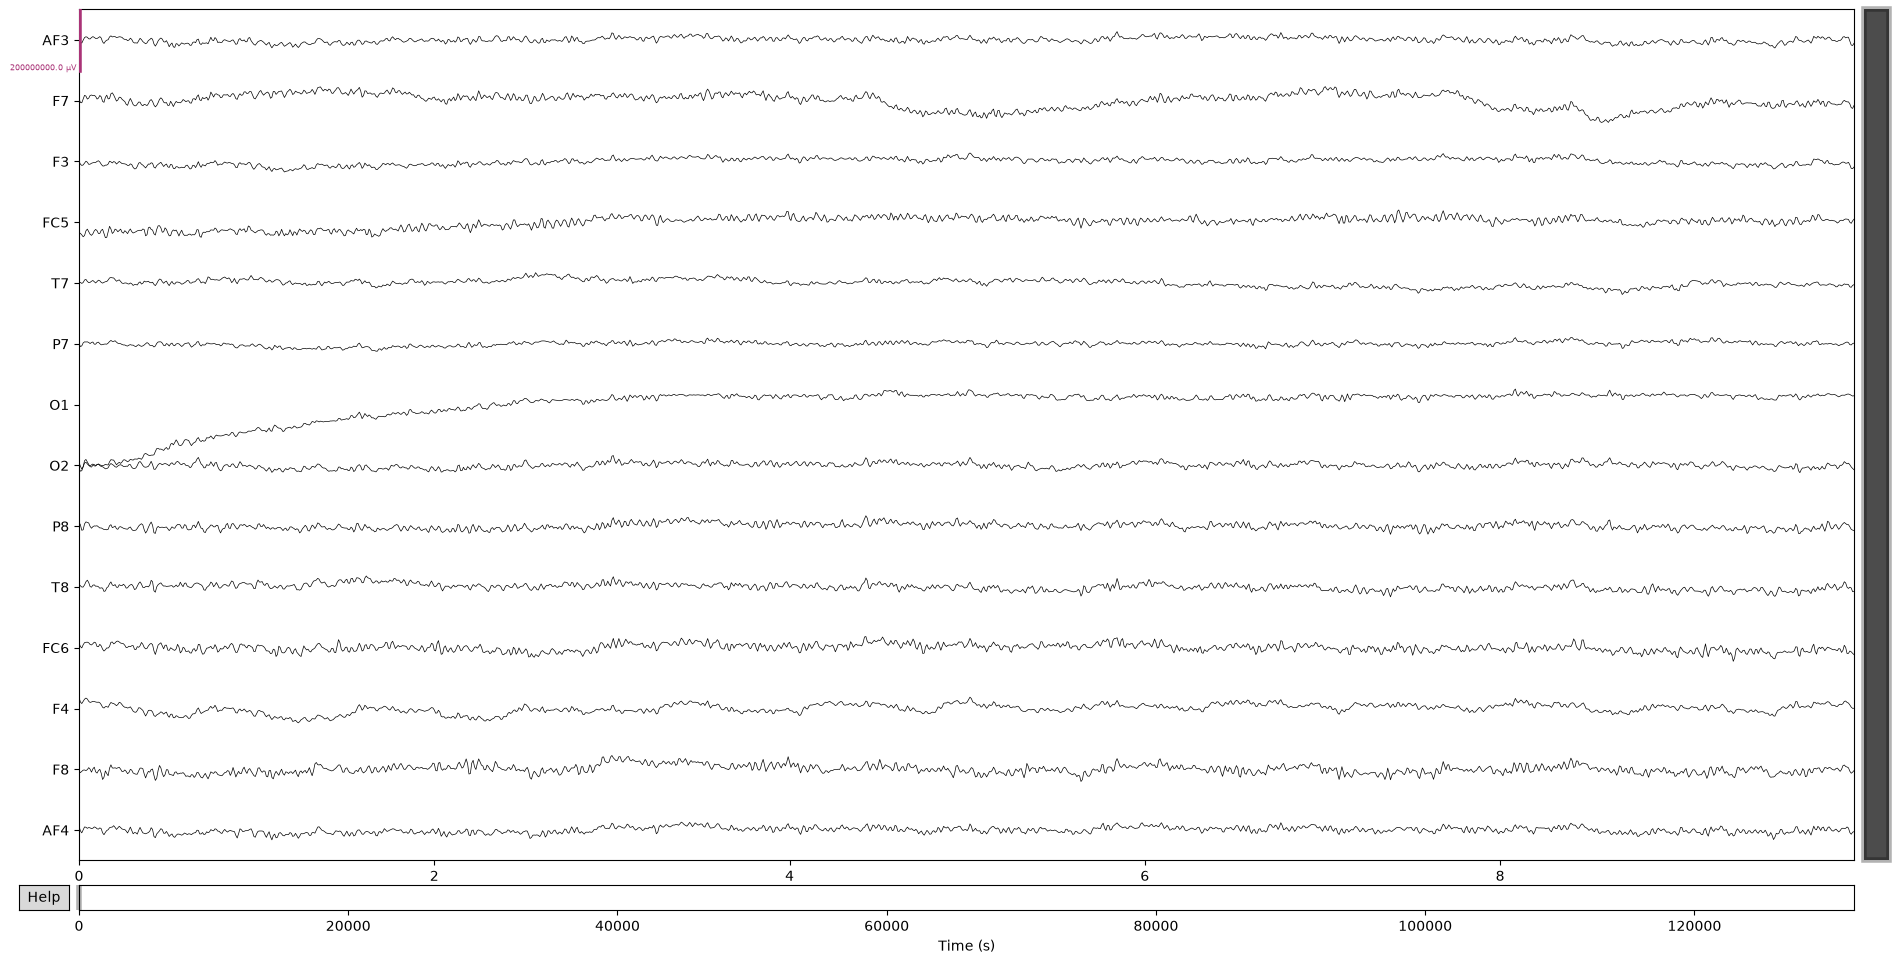

Effective window size : 16.000 (s)
Plotting power spectral density (dB=True).


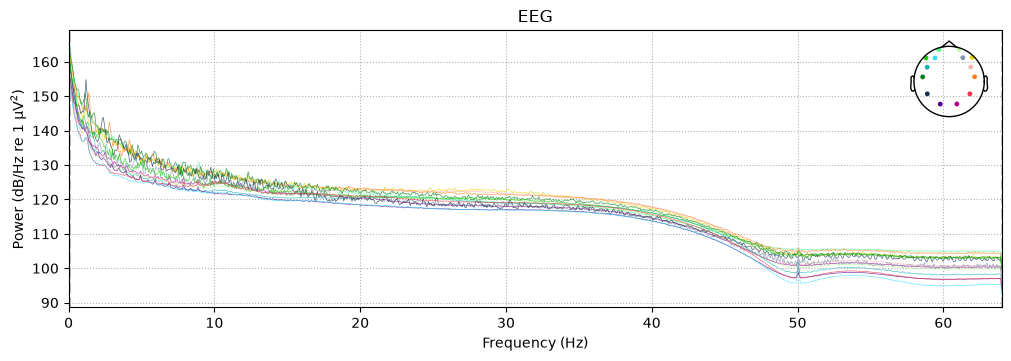

In [8]:
device_wise_raw['EP'].plot(scalings=dict(eeg=device_scalings['EP']))
device_wise_raw['EP'].compute_psd(picks=None, fmax=device_sampling_rates['EP']//2).plot(picks=None, exclude='bads', amplitude=False)
print('\n')

### MU device
Sparse dataset with a lot of jumps in the signal as of right now. It looks discontinously-sampled, meaning it looks worse right now before the epochoral split using the epochs computed already. Overall, considering better data is available, I may only use this if EP is not performing well and the cleaning looks okay. 

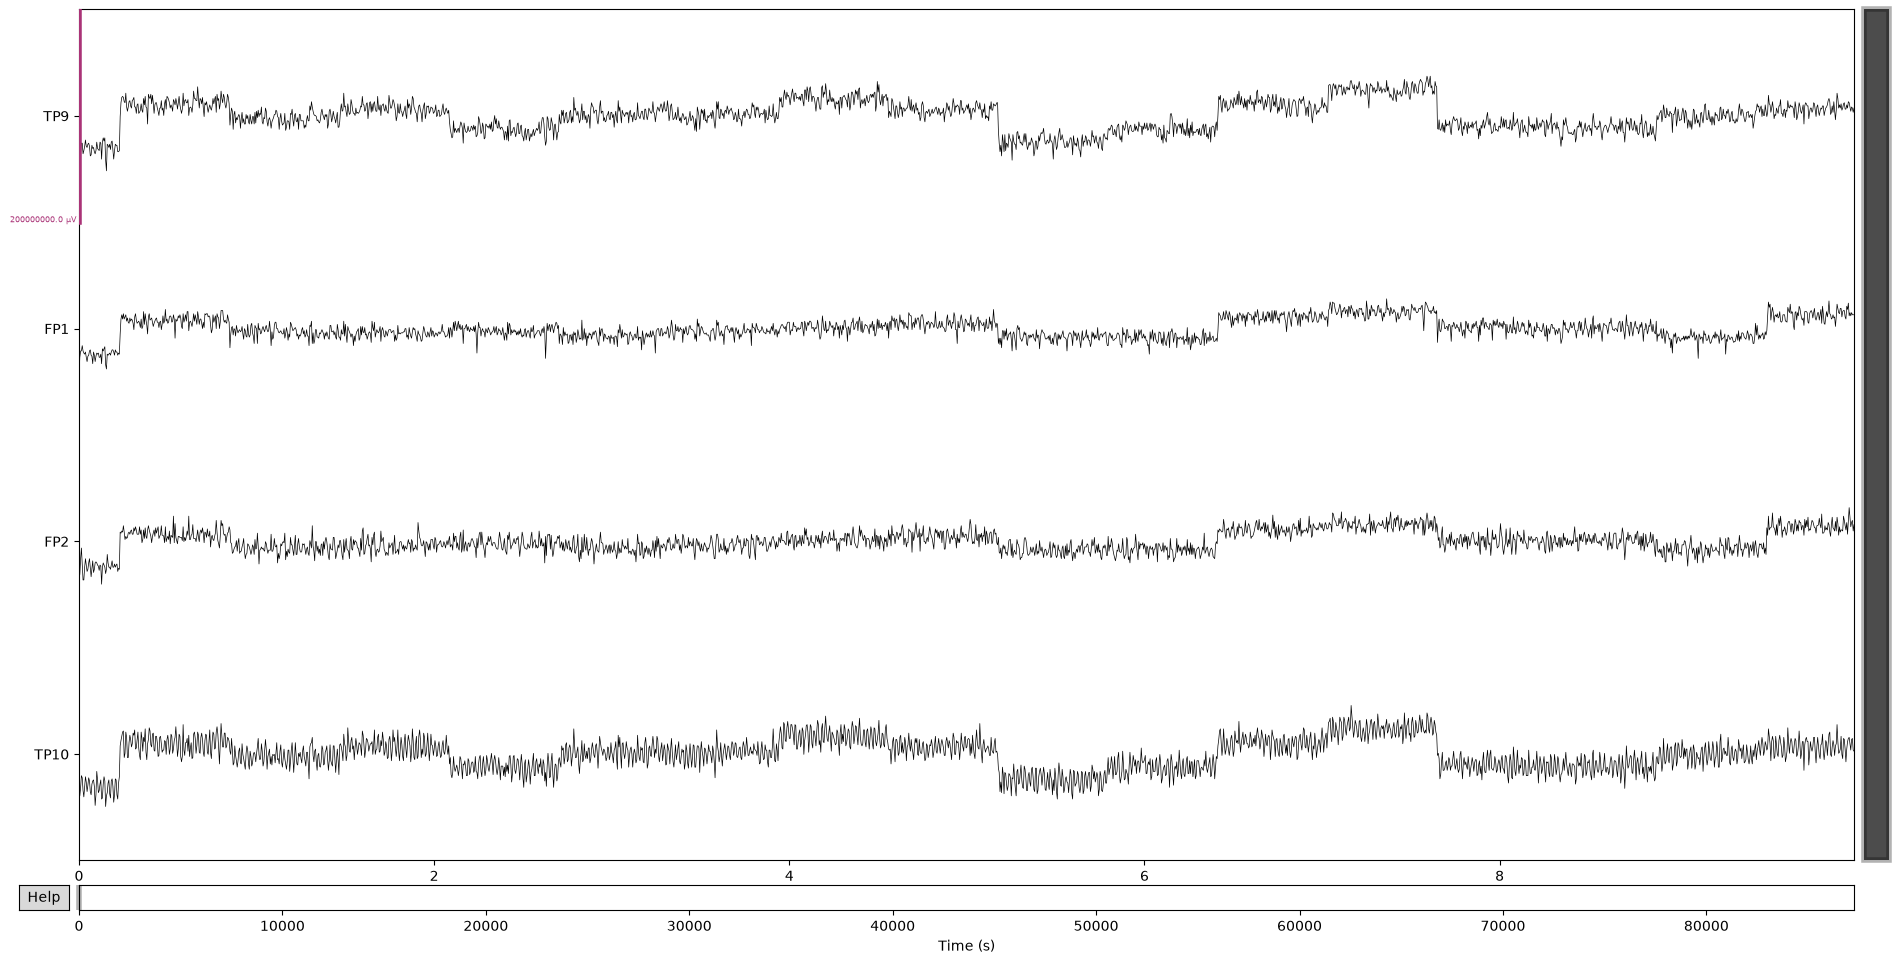

Effective window size : 9.309 (s)
Plotting power spectral density (dB=True).


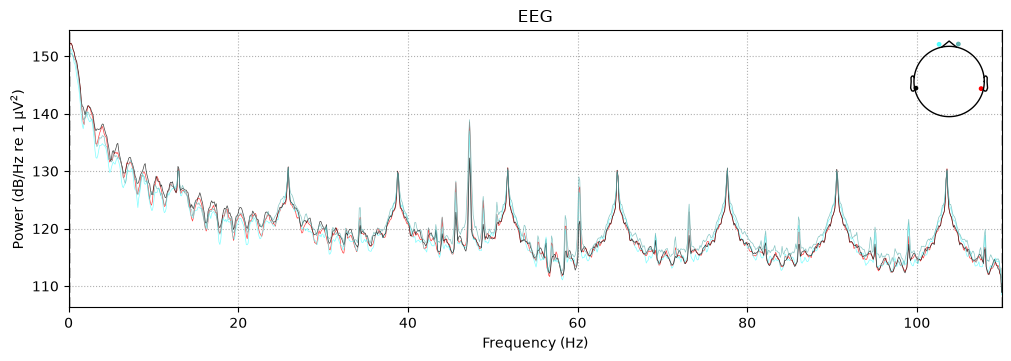

In [9]:
device_wise_raw['MU'].plot(scalings=dict(eeg=device_scalings['MU']))
device_wise_raw['MU'].compute_psd(picks=None, fmax=device_sampling_rates['MU']//2).plot(picks=None, exclude='bads', amplitude=False)
print('\n')

### IN device
Overall this data is sparser than the EP data and looks a bit more noisy. I may use this if the EP data alone is not sufficient. 

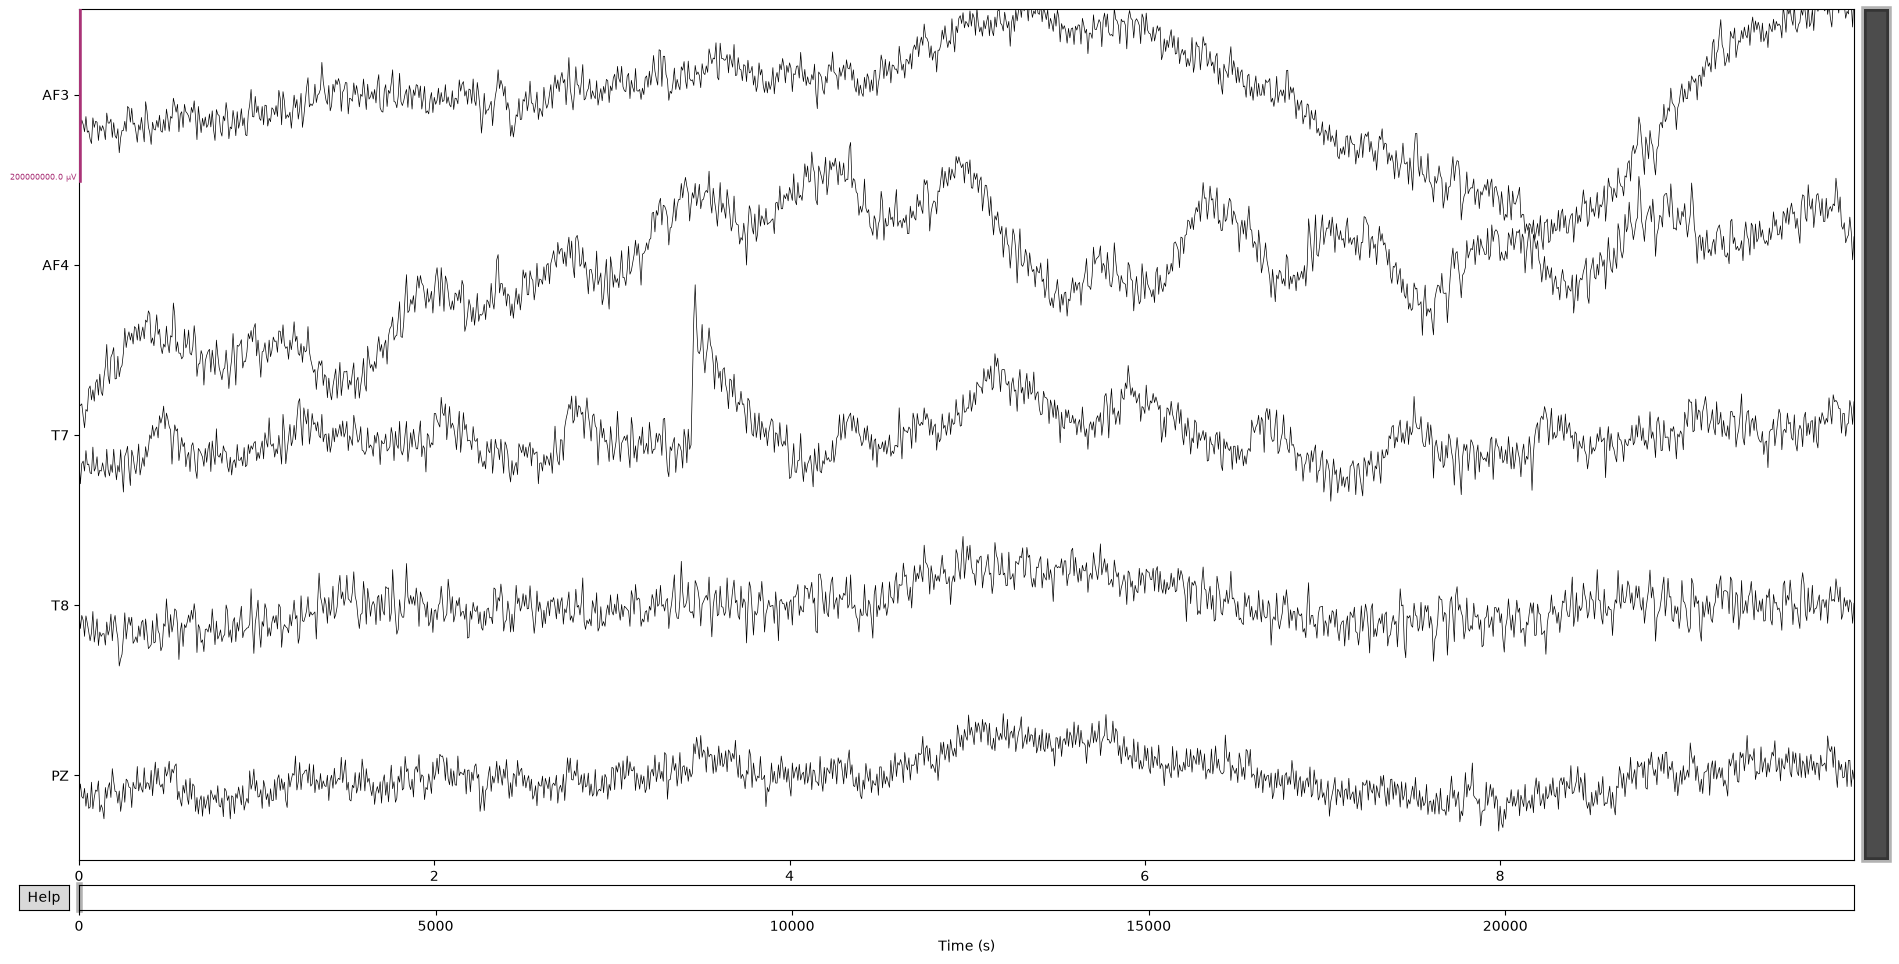

Effective window size : 16.000 (s)
Plotting power spectral density (dB=True).


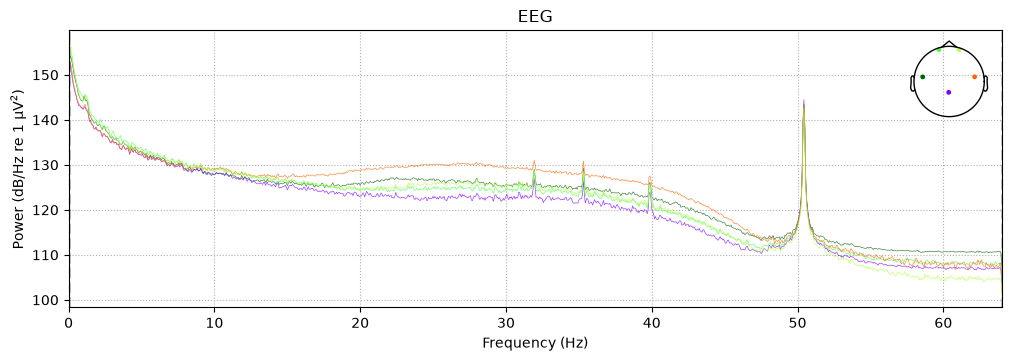

In [10]:
device_wise_raw['IN'].plot(scalings=dict(eeg=device_scalings['IN']))
device_wise_raw['IN'].compute_psd(picks=None, fmax=device_sampling_rates['IN']//2).plot(picks=None, exclude='bads', amplitude=False)
print('\n')

## Preprocessing (EP only)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.10
- Lower transition bandwidth: 0.10 Hz (-6 dB cutoff frequency: 0.05 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 4225 samples (33.008 s)



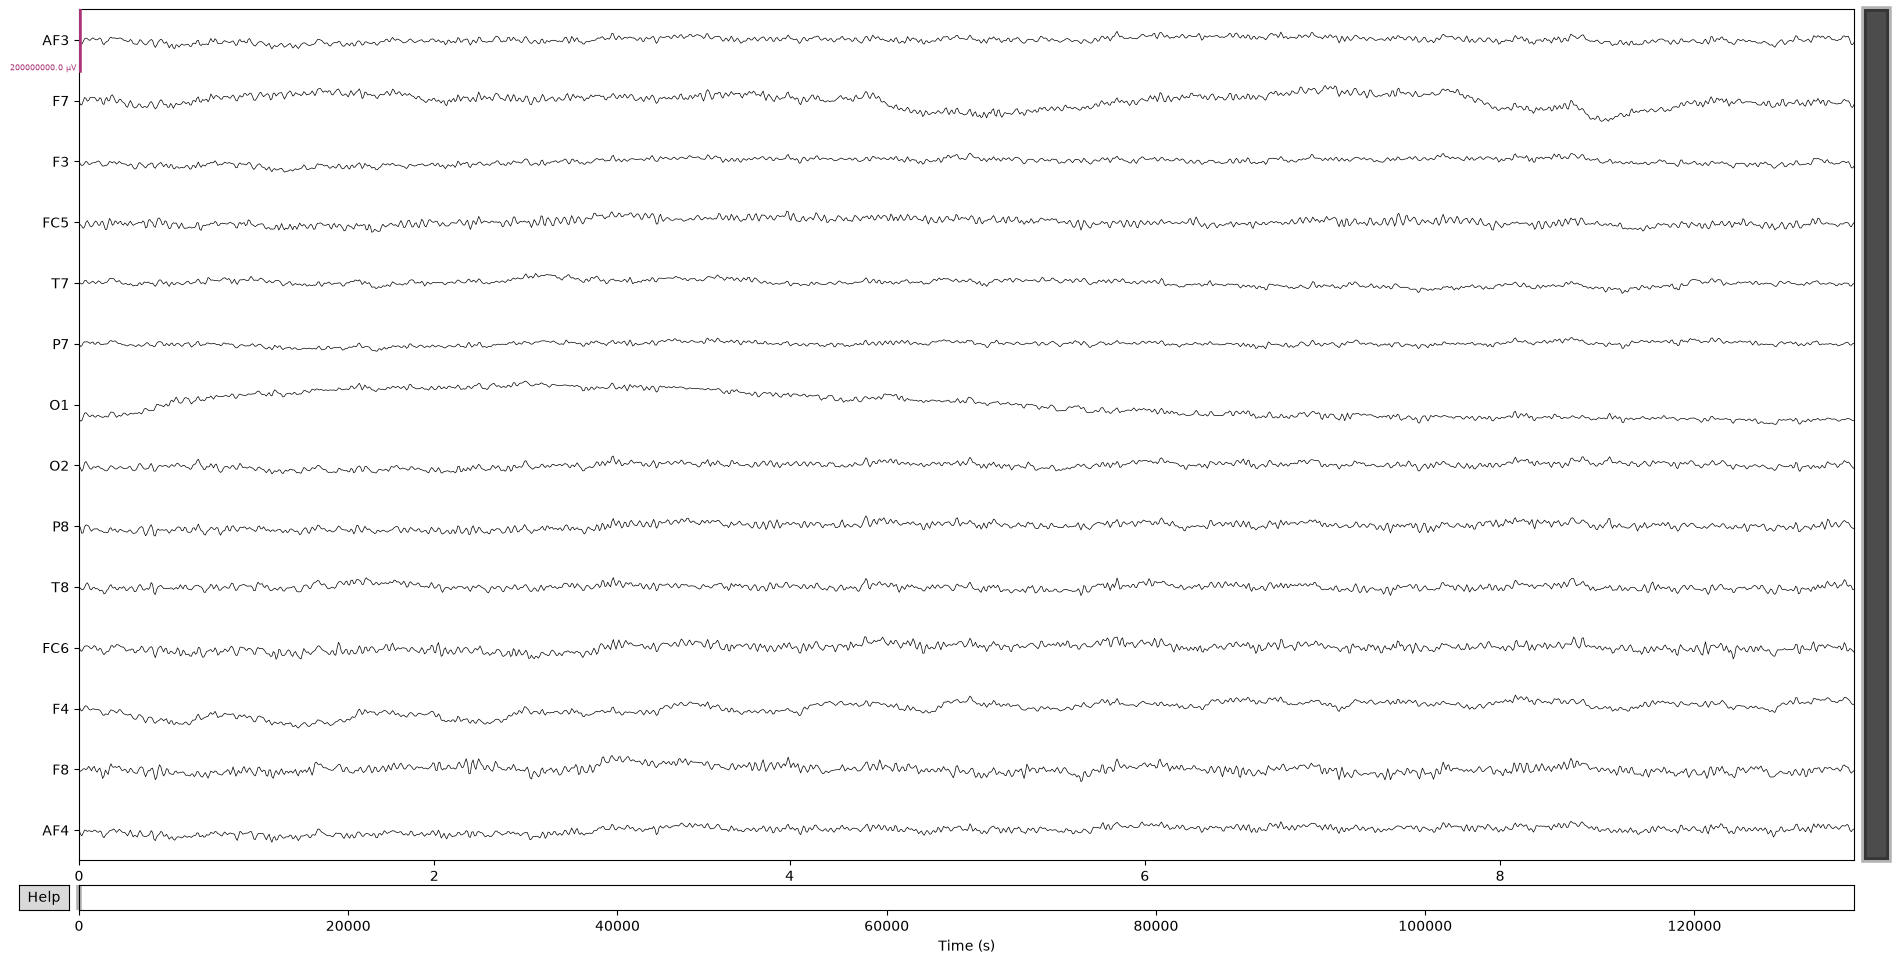

Effective window size : 16.000 (s)
Plotting power spectral density (dB=True).


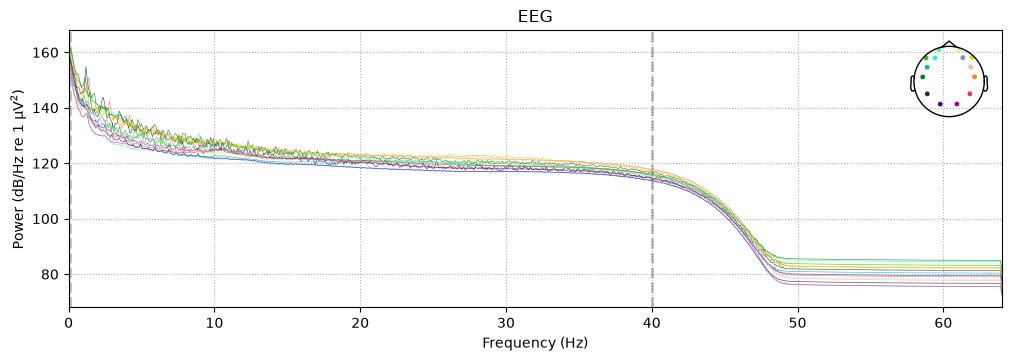

In [11]:
# %matplotlib qt
%matplotlib inline

#we close other raw elements
device_wise_raw['MW'].close()
device_wise_raw['IN'].close()
device_wise_raw['MU'].close()

#filter for ERP relevant frequency band with highest pass which eliminates slow-drift
filtered = device_wise_raw['EP'].copy().filter(l_freq = 0.1, h_freq = 40)

filtered.plot(scalings=dict(eeg=device_scalings['EP']))
filtered.compute_psd(picks=None, fmax=device_sampling_rates['EP']//2).plot(picks=None, exclude='bads', amplitude=False)
print('\n')

### 
Since single-channel problems arise but overall no channel appears bad, we will aim to reconstruct them after removing as much EOG and ECG artifacts as possible.

In [12]:
#automatic bad channel detection
bad_channels = mne.preprocessing.find_bad_channels_lof(filtered, n_neighbors=14, threshold=1.5, return_scores=True)
print('Found: ', bad_channels[0])

LOF: Detected bad channel(s): []
Found:  []


In [13]:
#detecting ecg artefacts
# ecg_epochs = mne.preprocessing.create_ecg_epochs(filtered) #without specific channel this only works for MEG data
# ecg_epochs.plot_image(combine='mean')

# avg_ecg_epochs = ecg_epochs.average()
# avg_ecg_epochs.plot_topomap(times=np.linspace(-0.05, 0.05, 11))

# avg_ecg_epochs.plot_joint(times=np.linspace(-0.05, 0.05, 11))
# print('\n')

In [14]:
#detecting eog artefacts
# eog_epochs = mne.preprocessing.create_eog_epochs(filtered, baseline=(-0.5, -0.2)) #no EOG channel so not usable for this dataset
# eog_epochs.plot_image(combine='mean')
# eog_epochs.average().plot_joint()
# print('\n')

In [15]:
#powerline noise removal
filtered = filtered.notch_filter(freqs=[60]) #powerline noise, likely unecessary due to initial PSD

#no downsampling used here since memory usage is okay and EP sampling rate is already lower
# filtered.resample(...)

#we fold the raw data into epochs now using epochs[device]
epochs = mne.Epochs(filtered, device_wise_events['EP'], preload=True)
epochs = epochs.drop_bad()

Filtering raw data in 1 contiguous segment
Setting up band-stop filter from 59 - 61 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 59.35
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 59.10 Hz)
- Upper passband edge: 60.65 Hz
- Upper transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 60.90 Hz)
- Filter length: 845 samples (6.602 s)

Not setting metadata
65034 matching events found
Setting baseline interval to [-0.203125, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 65034 events and 91 original time points ...
1 bad epochs dropped


In [16]:
ar = AutoReject(
    n_interpolate=[0],         # Test interpolating 1 or 2 bad channels
    consensus=[0.1, 0.2],    # Drop epoch if >10-30% of channels are bad
    picks="eeg",
    random_state=42,
    n_jobs=-1
)

epochs_clean = ar.fit_transform(epochs)

reject_log = ar.get_reject_log(epochs)

# Retrieve bad/dropped epoch indices:
dropped_epoch_indices = [i for i, bad in enumerate(reject_log.bad_epochs) if bad] #No 1 to 1 correspondance with MNIST so not needed

Running autoreject on ch_type=eeg


c:\Users\marlo\anaconda3\envs\neural_analysis\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| Creating augmented epochs : 14/14 [00:05<00:00,    2.58it/s]
100%|██████████| Computing thresholds ... : 14/14 [00:00<00:00,  621.02it/s]

  0%|          | Repairing epochs : 0/0 [00:00<?,       ?it/s]

  0%|          | Repairing epochs : 0/0 [00:00<?,       ?it/s]






















100%|██████████| Fold : 10/10 [00:05<00:00,    1.87it/s]
100%|██████████| n_interp : 1/1 [00:06<00:00,    6.21s/it]






Estimated consensus=0.10 and n_interpolate=0



  0%|          | Repairing epochs : 0/0 [00:00<?,       ?it/s]


Dropped 6513 epochs: 14, 74, 89, 104, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 162, 164, 195, 224, 237, 239, 252, 253, 254, 314, 358, 359, 419, 420, 434, 441, 448, 449, 463, 464, 465, 475, 479, 481, 482, 484, 485, 487, 488, 490, 491, 492, 493, 494, 554, 569, 584, 599, 614, 617, 627, 644, 674, 678, 689, 694, 704, 716, 718, 719, 725, 745, 749, 754, 755, 760, 763, 764, 779, 794, 824, 826, 837, 854, 869, 884, 899, 914, 944, 959, 974, 975, 986, 989, 1004, 1019, 1034, 1049, 1066, 1067, 1074, 1076, 1077, 1078, 1079, 1089, 1094, 1098, 1099, 1100, 1101, 1103, 1104, 1106, 1109, 1154, 1184, 1199, 1214, 1244, 1250, 1257, 1258, 1259, 1273, 1334, 1349, 1364, 1394, 1406, 1409, 1414, 1424, 1439, 1446, 1454, 1455, 1456, 1458, 1459, 1460, 1464, 1467, 1469, 1484, 1514, 1517, 1520, 1521, 1526, 1528, 1529, 1536, 1539, 1544, 1546, 1549, 1550, 1553, 1559, 1575, 1579, 1664, 1679, 1724, 1739, 1754, 1757, 1769, 1814, 1829, 1844, 1855, 1856, 1857, 1858, 1874, 1890, 1900, 19

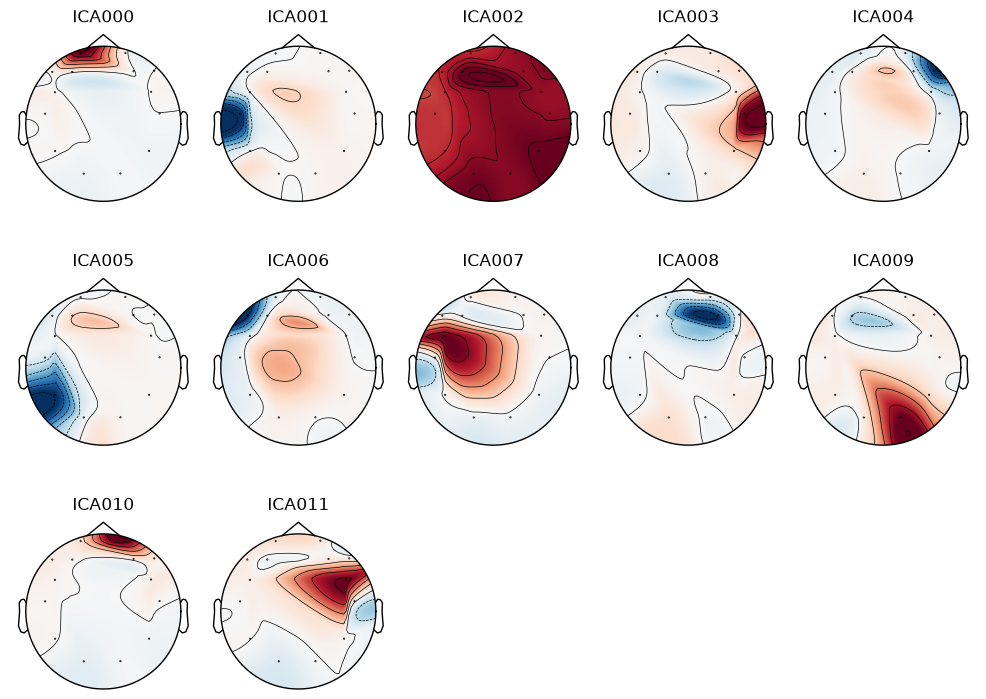

In [18]:
reject_threshold = get_rejection_threshold(epochs)

#we fit ICA on the higher frequencies of the raw data and then exlcude IC for epoch data which signify EOG/EMG artefacts
ica = mne.preprocessing.ICA(
    n_components=0.95, 
    method="picard", 
    max_iter=800, 
    random_state=42
)
ica.fit(device_wise_raw['EP'].copy().filter(l_freq=0.1, h_freq=40.0), reject=reject_threshold, verbose=False)
ica.plot_components()
print('\n')

Analysis:
 * IC 0&10 likely EOG
 * IC 1,3,4,5,6, and 11 likely muscular activity and 
 * IC 2,7,8, and 9 likely the best IC for neural activity

Due to low channel count and poor quality I will only remove obvious EOG IC 0 and 10 after inspection.

    Using multitaper spectrum estimation with 7 DPSS windows
Not setting metadata
1000 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
1000 matching events found
No baseline correction applied
0 projection items activated


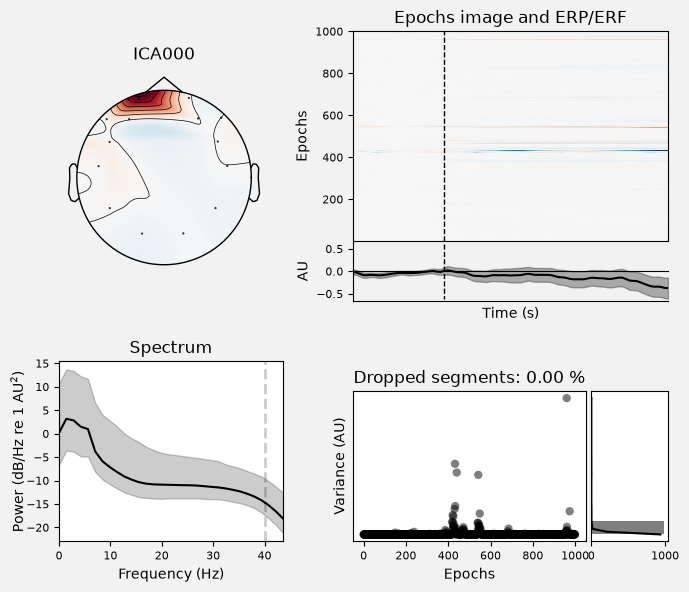

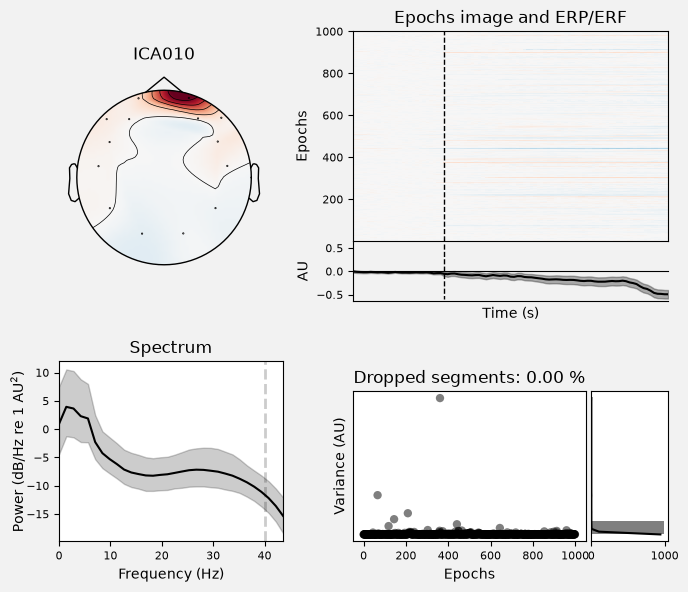

In [24]:
# %matplotlib qt
%matplotlib inline

#plotting components 0 and 10 as they are most likely EOG
ica.plot_properties(
    epochs[:1000],
    picks=[0, 10],
    psd_args=dict(fmax=45.0),
    show=True
)
print('\n')

In [25]:
ica.exclude = [0, 10] #excluded 0 and 10 as EOG artefacts
cleaned_epochs = ica.apply(epochs.copy()) #we interpolate with ICA on the epoch data

#final cleanup of bad events using autoreject
#due to the low amount of channels rejection parameters are limited here for interpolation and consensus
ar_final = AutoReject(
    n_interpolate=[1, 2],
    consensus=[0.15, 0.3, 0.45],
    cv=5,
    random_state=42,
    n_jobs=-1
)

final_epochs, reject_log = ar_final.fit_transform(cleaned_epochs, return_log=True)

Applying ICA to Epochs instance


C:\Users\marlo\AppData\Local\Temp\ipykernel_47984\165620484.py:2: RuntimeWarning: The data you passed to ICA.apply() was baseline-corrected. Please note that ICA can introduce DC shifts, therefore you may wish to consider baseline-correcting the cleaned data again.
  cleaned_epochs = ica.apply(epochs.copy()) #we interpolate with ICA on the epoch data


    Transforming to ICA space (12 components)
    Zeroing out 2 ICA components
    Projecting back using 14 PCA components
Running autoreject on ch_type=eeg


100%|██████████| Creating augmented epochs : 14/14 [00:04<00:00,    2.92it/s]
100%|██████████| Computing thresholds ... : 14/14 [00:00<00:00, 27816.32it/s]

  0%|          | Repairing epochs : 0/0 [00:00<?,       ?it/s]













100%|██████████| Repairing epochs : 12/12 [00:00<00:00,   25.78it/s]












100%|██████████| Fold : 5/5 [00:03<00:00,    1.40it/s]





































































































































































































100%|██████████| Repairing epochs : 365/365 [00:04<00:00,   74.58it/s]












100%|██████████| Fold : 5/5 [00:03<00:00,    1.53it/s]
100%|██████████| n_interp : 2/2 [00:15<00:00,    7.58s/it]






Estimated consensus=0.45 and n_interpolate=1















100%|██████████| Repairing epochs : 12/12 [00:00<00:00,   35.69it/s]


Dropped 1055 epochs: 149, 358, 463, 464, 481, 482, 484, 487, 490, 493, 494, 689, 725, 1214, 1446, 1454, 1455, 1456, 1458, 1460, 1464, 1467, 1469, 1529, 1539, 1918, 1919, 2040, 2043, 2044, 2049, 2050, 2051, 2053, 2054, 2189, 2204, 2264, 2268, 2269, 2370, 2377, 2381, 2384, 2387, 2393, 2397, 2579, 2594, 2684, 2699, 2709, 2714, 2759, 2767, 2770, 2774, 2984, 3032, 3554, 3895, 3914, 3989, 4049, 4094, 4184, 4186, 4187, 4197, 4199, 4214, 4244, 4424, 4430, 4439, 4544, 4558, 4709, 4813, 5039, 5043, 5044, 5083, 5114, 5159, 5204, 5249, 5414, 5490, 5659, 6005, 6209, 6314, 6389, 6404, 6567, 6599, 6794, 6799, 6800, 6804, 6921, 6928, 6975, 6976, 6980, 6981, 6983, 6984, 6986, 6989, 7004, 7124, 7214, 7274, 7304, 7319, 7332, 7379, 7439, 7874, 7889, 8144, 8294, 8309, 8414, 8463, 8489, 8493, 8609, 8631, 8639, 8714, 8804, 8864, 8879, 8880, 8881, 8882, 8884, 8885, 8886, 8888, 8889, 8891, 8892, 8893, 8894, 9078, 9085, 9179, 9189, 9323, 9419, 9584, 9698, 9779, 9784, 9794, 9914, 9923, 9925, 9926, 9929, 9985, 10

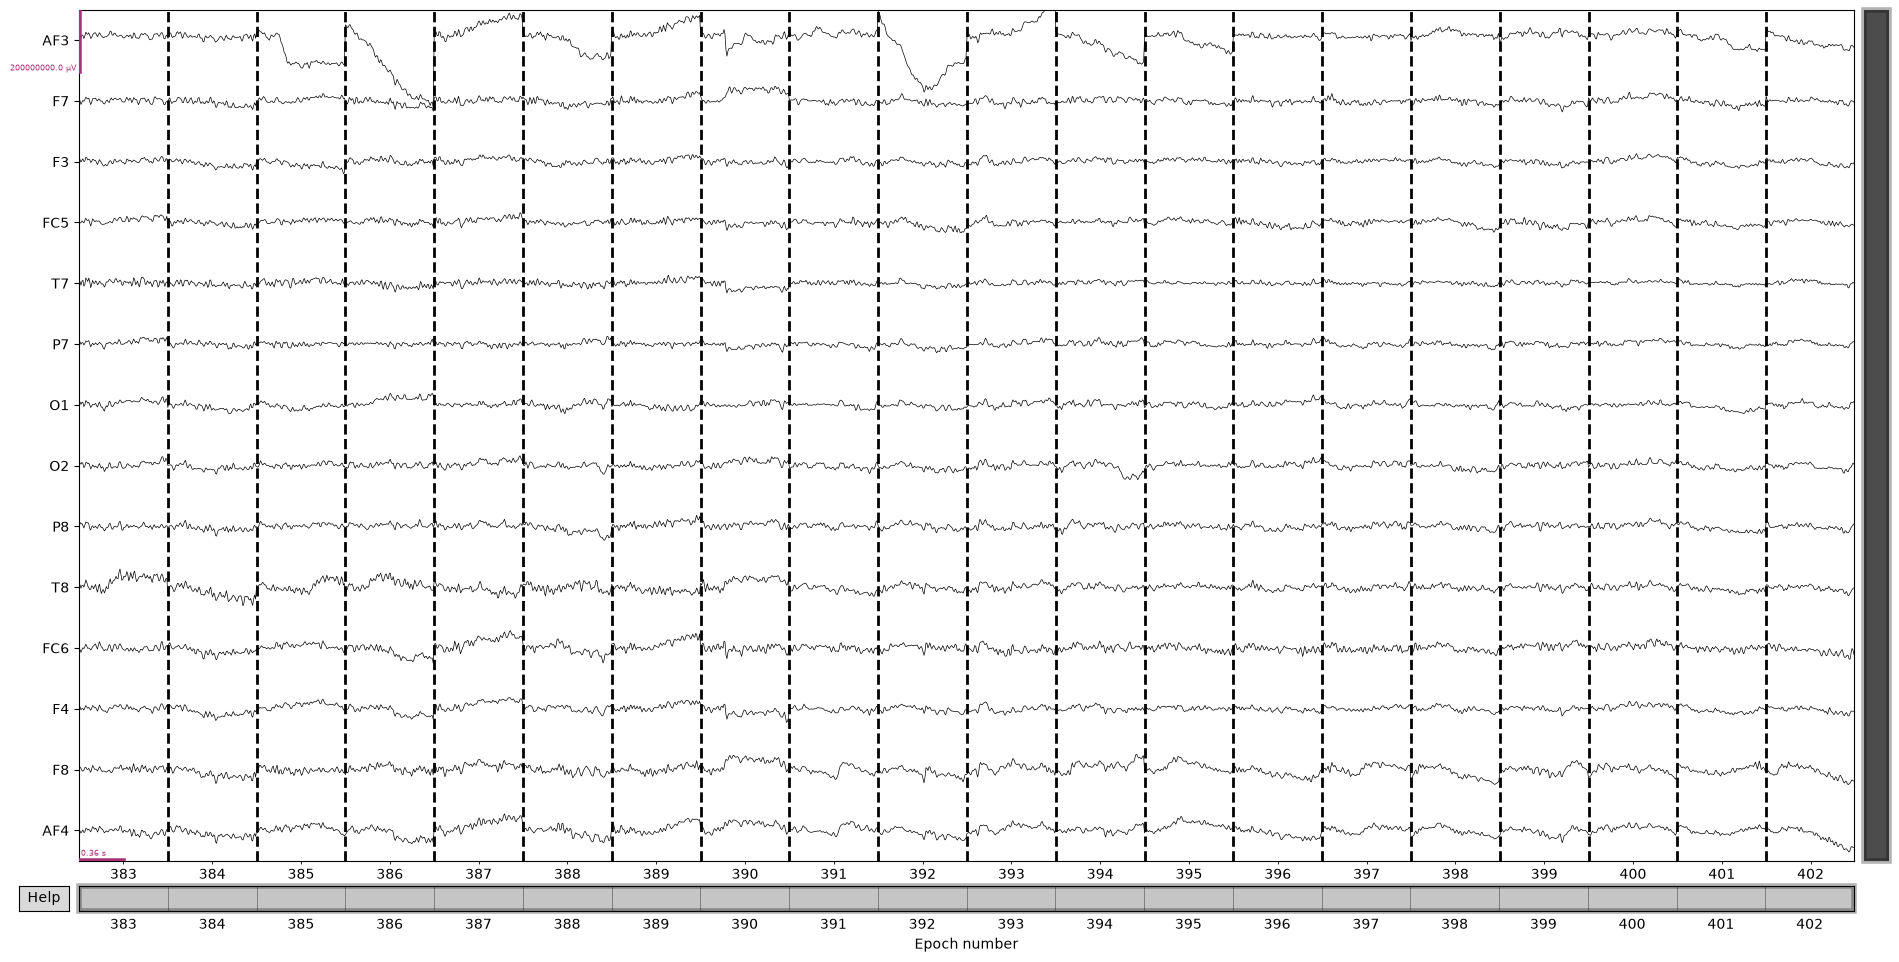

In [29]:
# %matplotlib qt
%matplotlib inline

#finally we plot the rejected epochs here for clarity on the filtering
epochs[~reject_log.bad_epochs][380:400].plot(scalings=dict(eeg=device_scalings['EP'])) #selected 380-400 window for showcase purposes here, rejection looks good
print('\n')

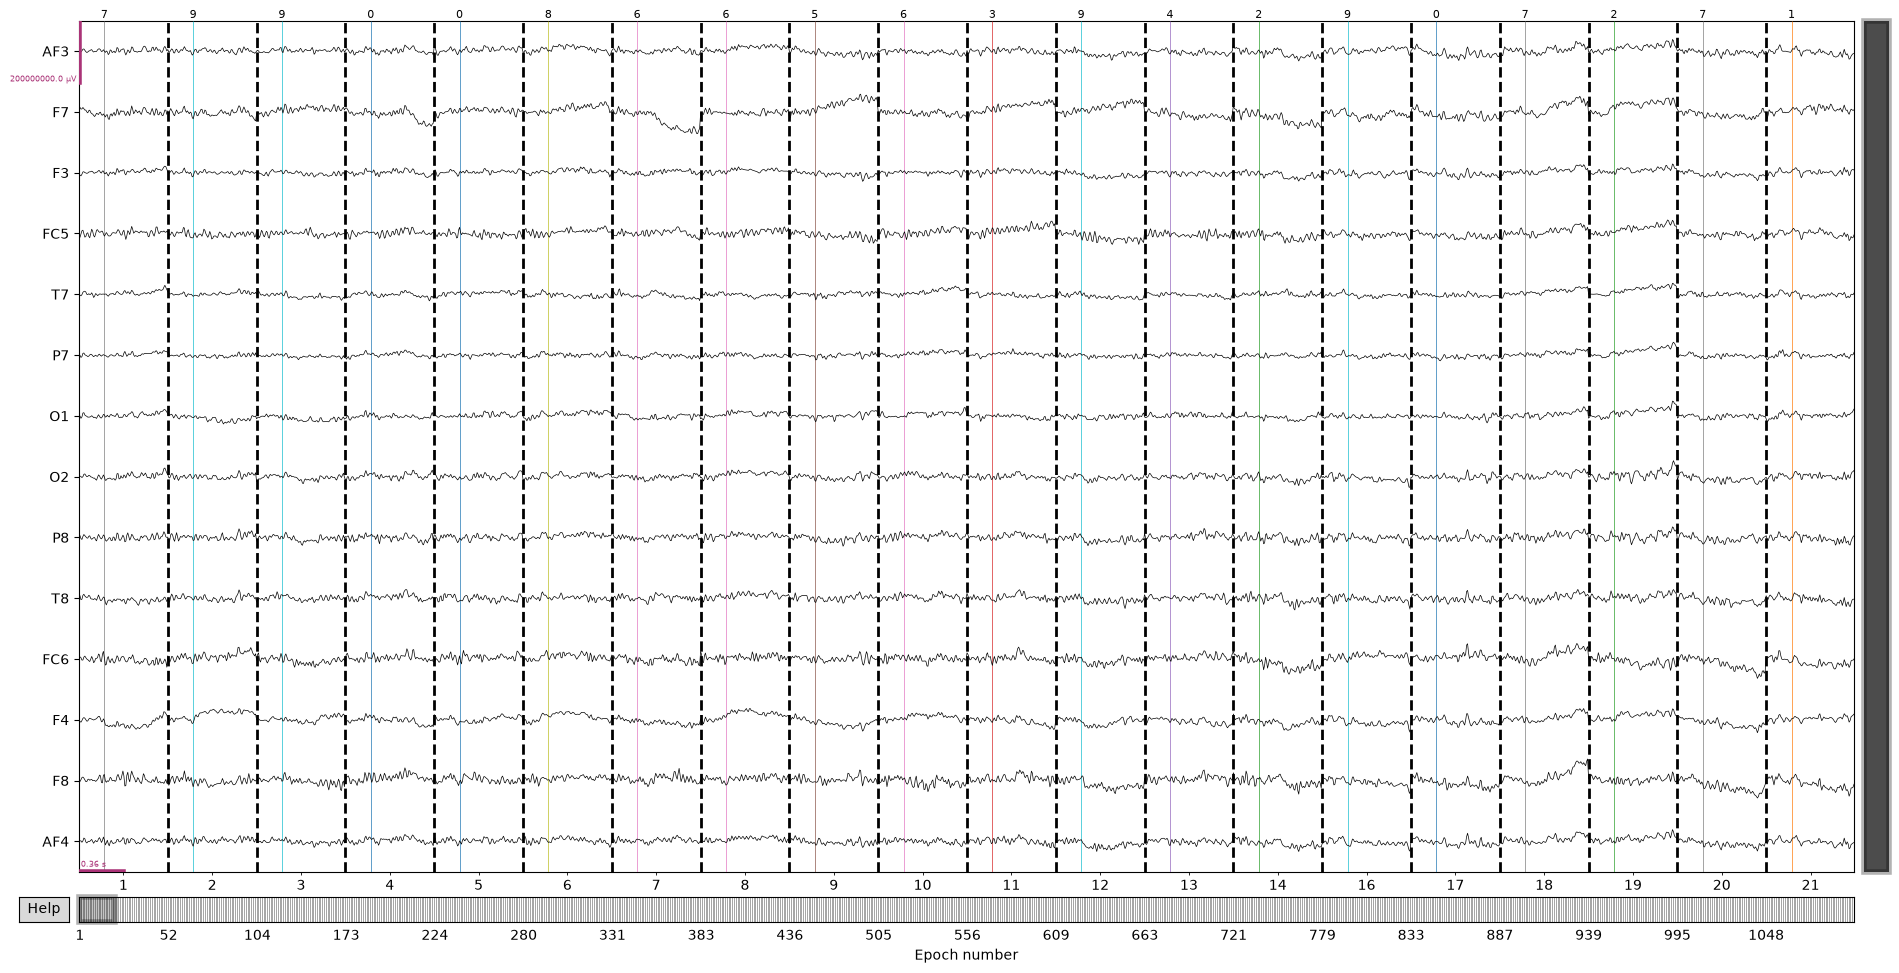

In [30]:
# %matplotlib qt
%matplotlib inline

#we inspect the epoch data to see if most bad events were rejected
events_sel = mne.pick_events(device_wise_events['EP'])

i = 0 #sliding window parameter due to RAM limits for final data inspection
epochs_clean[i*1000:i*1000+1000].plot(scalings=device_scalings['EP'], events=events_sel[i*1000:i*1000+1000], n_epochs=20)
print('\n')

## Discussion
Due to the low number of available channels, lack of EOG and ECG, and bad quality, the data still looks noisy. I will test this data and also attempt to utilize the more recent larger dataset later for better results.

In [31]:
epochs_clean.save('./data/MNIST_small_epochs.fif')

C:\Users\marlo\AppData\Local\Temp\ipykernel_47984\821687829.py:1: RuntimeWarning: This filename (./data/MNIST_small_epochs.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs_clean.save('./data/MNIST_small_epochs.fif')


[WindowsPath('c:/Users/marlo/GitHubRepos/NeuralDataAnalysisTools2026/EEG/data/MNIST_small_epochs.fif')]

### References and Thanks to
Vivancos, D. (2020). *MindBigData 2022: The "MNIST" of brain digits* (Version 1.0) [Data set]. MindBigData. http://mindbigdata.com/opendb/index.html

D’Ascenzo, F., Del Fabro, B., Finisguerra, A., & Urgesi, C. (2023). *Best practices in EEG analysis: Preprocessing, modeling, and machine learning*. arXiv. https://doi.org/10.48550/arXiv.2312.15286

Abibullaev, B. [Berdakh Abibullaev]. (2020, September 22nd). *L10: Overview of artifact and noise detection in EEG/MEG* [Video]. YouTube. https://www.youtube.com/watch?v=lcux-Fj-IYE

Abibullaev, B. [Berdakh Abibullaev ]. (2020, September 15th). *L8: MNE tutorial Part #1 - Load and Segment continuous EEG data* [Video]. YouTube. https://www.youtube.com/watch?v=IYuAPisoUeI